In [ ]:
import sys
import pandas as pd
import numpy as np
import os
import importlib
from src.eval_utils import full_evaluation
from src.modeltrainer import *
import matplotlib.pyplot as plt
import glob

# Reimporter les modules pour refléter les modifications
importlib.reload(sys.modules['src.eval_utils'])
importlib.reload(sys.modules['src.modeltrainer'])

sys.path.insert(0, './src')

In [2]:
# =============================================================================
# CELLULE 1 : IMPORT DES DONNÉES
# =============================================================================


# Configuration
DATA_PATH = 'data/processed_data_imputed.xlsx'
COLS_TO_DROP = ['patient_ids', 'feat_40', 'feat_82']

# Chargement des données
print("📂 Chargement des données...")

train_data = pd.read_excel(DATA_PATH, sheet_name='train')
cal_data = pd.read_excel(DATA_PATH, sheet_name='calibration')
test_data = pd.read_excel(DATA_PATH, sheet_name='test')

# Séparation features / target
X_train = train_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_train = train_data.iloc[:, -1]

X_cal = cal_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_cal = cal_data.iloc[:, -1]

X_test = test_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_test = test_data.iloc[:, -1]

print(f"✓ Données chargées:")
print(f"   - Train: {X_train.shape[0]} lignes, {X_train.shape[1]} features")
print(f"   - Calibration: {X_cal.shape[0]} lignes")
print(f"   - Test: {X_test.shape[0]} lignes")
print(f"   - Target distribution (train): {y_train.value_counts().to_dict()}")

📂 Chargement des données...
✓ Données chargées:
   - Train: 83555 lignes, 81 features
   - Calibration: 28381 lignes
   - Test: 28465 lignes
   - Target distribution (train): {0: 46672, 1: 36883}


In [ ]:
# =============================================================================
# CELLULE 2 : CHARGEMENT OU ENTRAÎNEMENT DU MODÈLE XGBoost
# =============================================================================


# Configuration
MODEL_DIR = 'models'
MODEL_TYPE = 'XGBoost'  # 'LogisticRegression', 'RandomForest', 'XGBoost'


# Initialiser le trainer
trainer = ModelML(
    x_train=X_train,
    x_test=X_test,
    y_train=y_train,
    y_test=y_test
)

# Chercher un modèle existant
existing_model = find_existing_model(MODEL_DIR, MODEL_TYPE)

if existing_model:
    print(f"📦 Modèle existant trouvé: {existing_model}")
    trainer.load_model(existing_model)
else:
    print(f"🔄 Aucun modèle {MODEL_TYPE} trouvé. Entraînement en cours...")
    
    trainer.tune_xgboost(
        param_grid={
            'n_estimators': [50, 100, 200],
            'max_depth': [3, 5, 7],
            'learning_rate': [0.01, 0.1],
            'subsample': [0.6, 0.8, 1.0]
        },
        method='random',
        n_iter=20,
        cv=5,
        scoring='roc_auc'
    )
    
    trainer.save_model()
    print(f"✓ Modèle entraîné et sauvegardé")

print(f"\n📊 Modèle actif: {trainer.model_name}")
print(f"   Paramètres: {trainer.best_params}")

🔄 Aucun modèle XGBoost trouvé. Entraînement en cours...

🔍 Recherche d'hyperparamètres (RANDOM)
   Modèle: xgboost_tuned
   Scoring: roc_auc
   CV folds:  5
   Paramètres testés: ['n_estimators', 'max_depth', 'learning_rate', 'subsample']
Fitting 5 folds for each of 20 candidates, totalling 100 fits

✓ Meilleurs paramètres trouvés:
   - subsample:  0.8
   - n_estimators:  200
   - max_depth:  7
   - learning_rate:  0.1
   - Best CV Score (roc_auc): 0.9864

📊 Résultats:
   - Train Accuracy: 0.9588
   - Test Accuracy:  0.6930
✓ Modèle sauvegardé: models/xgboost_tuned.pkl
✓ Paramètres sauvegardés: models/xgboost_tuned_params.json
✓ Modèle entraîné et sauvegardé

📊 Modèle actif: xgboost_tuned
   Paramètres: {'subsample': 0.8, 'n_estimators': 200, 'max_depth': 7, 'learning_rate': 0.1}



📊 ÉVALUATION SUR LE TRAIN SET

🔍 ÉVALUATION COMPLÈTE:  xgboost_tuned_train
📊 MÉTRIQUES D'ÉVALUATION

🎯 Métriques de Classification:
----------------------------------------
   Accuracy                 : 0.9588
   Balanced_Accuracy        : 0.9574
   Precision                : 0.9613
   Recall_Sensitivity       : 0.9448
   Specificity              : 0.9699
   F1_Score                 : 0.9530
   Matthews_Corr_Coef       : 0.9165
   Cohen_Kappa              : 0.9164

📈 Métriques Probabilistes:
----------------------------------------
   ROC_AUC                  : 0.9932
   PR_AUC                   : 0.9918
   Brier_Score              : 0.0448
   Log_Loss                 : 0.1773

📋 RAPPORT DE CLASSIFICATION
              precision    recall  f1-score   support

    Classe 0       0.96      0.97      0.96     46672
    Classe 1       0.96      0.94      0.95     36883

    accuracy                           0.96     83555
   macro avg       0.96      0.96      0.96     83555
weighted avg

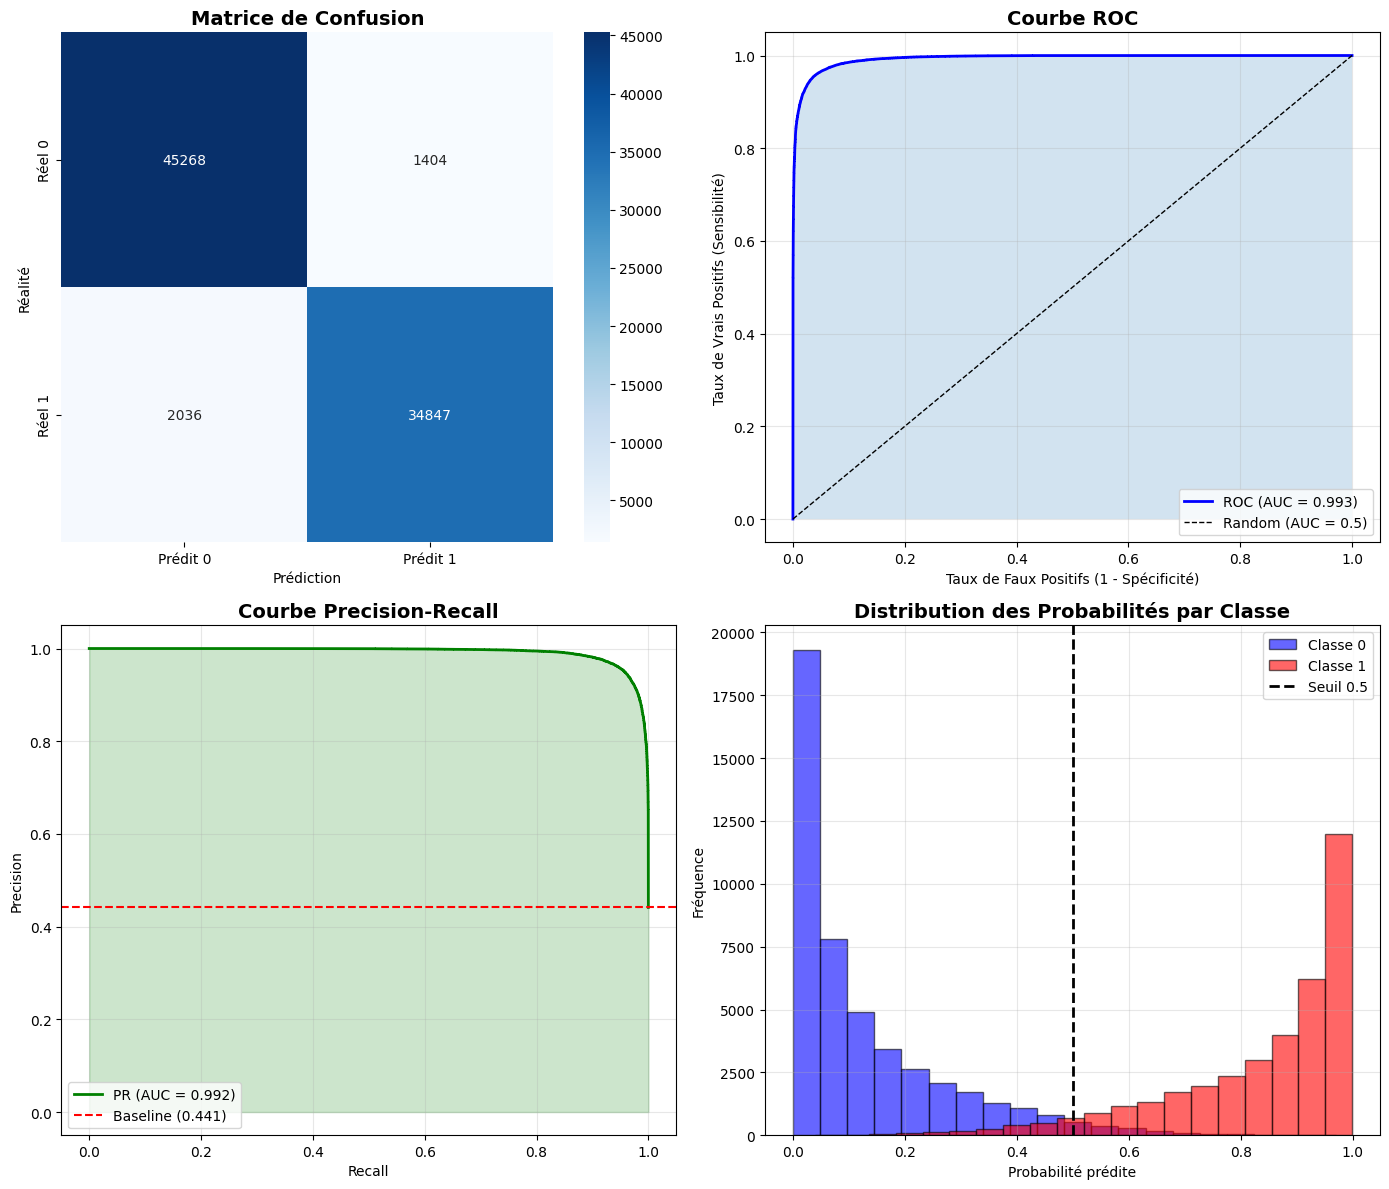

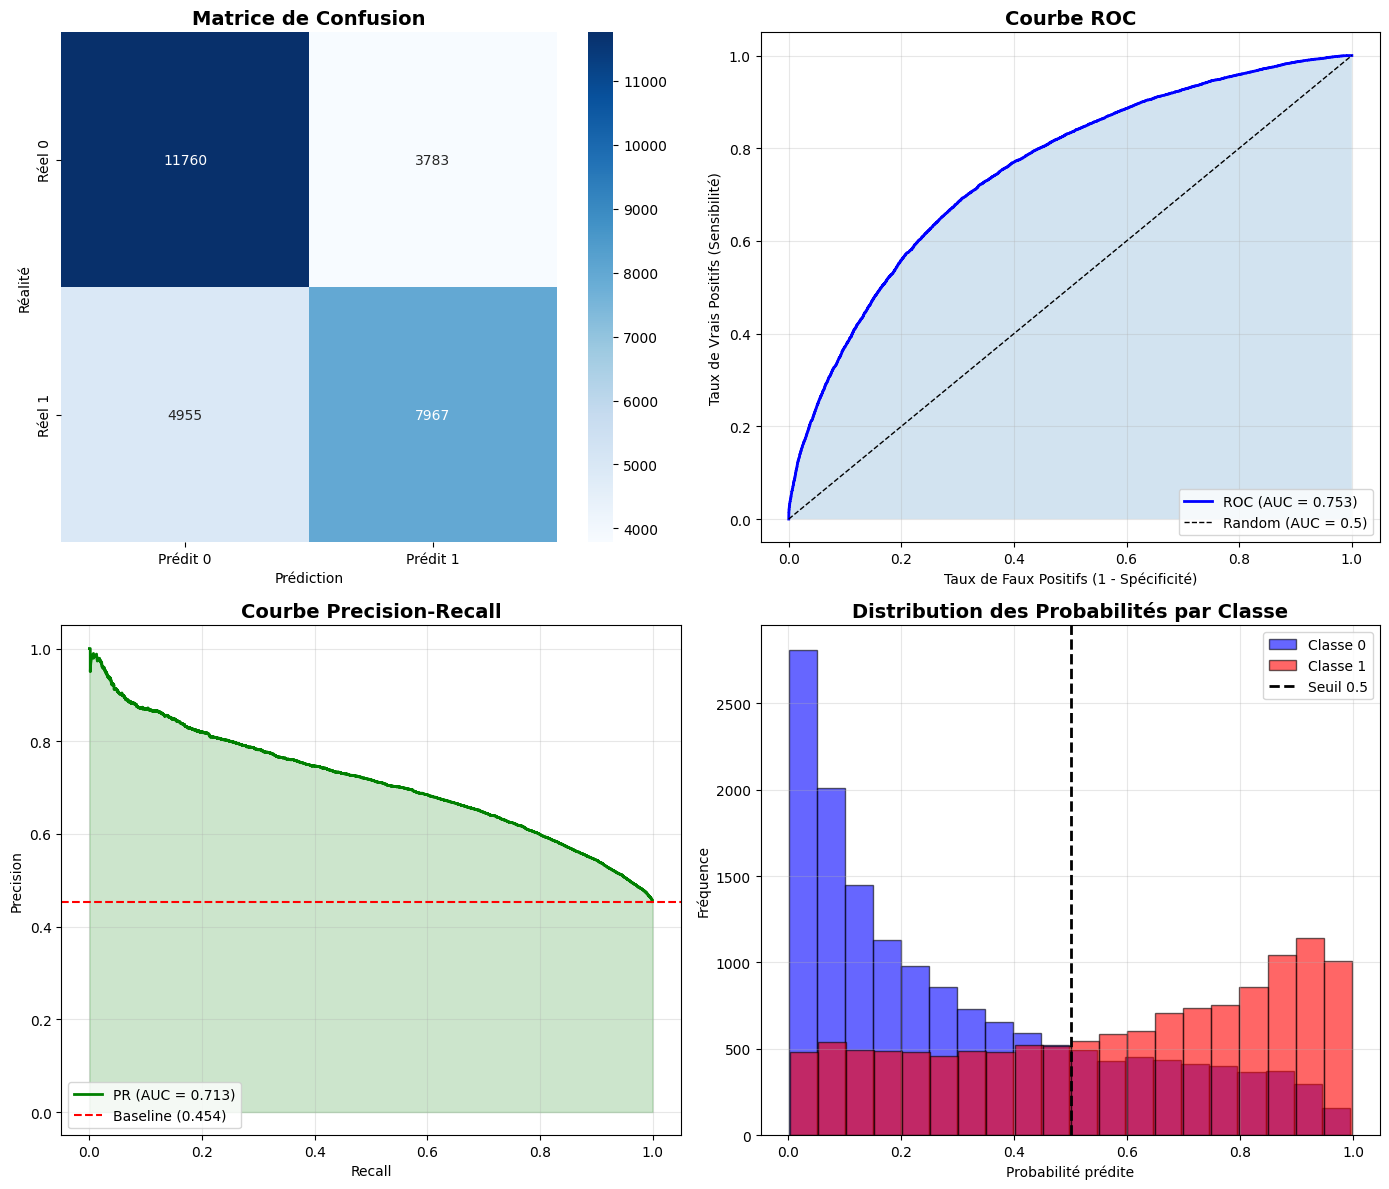


📈 COMPARAISON TRAIN vs TEST
Métrique                         Train         Test         Diff
----------------------------------------------------------------------
Accuracy                        0.9588       0.6930      +0.2658
Balanced_Accuracy               0.9574       0.6866      +0.2708
Precision                       0.9613       0.6780      +0.2832
Recall_Sensitivity              0.9448       0.6165      +0.3283
Specificity                     0.9699       0.7566      +0.2133
F1_Score                        0.9530       0.6458      +0.3071
Matthews_Corr_Coef              0.9165       0.3774      +0.5391
Cohen_Kappa                     0.9164       0.3760      +0.5403
ROC_AUC                         0.9932       0.7533      +0.2400
PR_AUC                          0.9918       0.7126      +0.2792
Brier_Score                     0.0448       0.2106      -0.1658
Log_Loss                        0.1773       0.6339      -0.4566


In [4]:
# =============================================================================
# CELLULE 3 : ÉVALUATION COMPLÈTE SUR LE TRAIN ET TEST SET
# =============================================================================

# --- Évaluation sur le TRAIN SET ---
print("\n" + "="*70)
print("📊 ÉVALUATION SUR LE TRAIN SET")
print("="*70)

y_pred_train = trainer.predict(X_train)
y_proba_train = trainer.predict_proba(X_train)[:, 1]

metrics_train = full_evaluation(
    y_true=y_train,
    y_pred=y_pred_train,
    y_proba=y_proba_train,
    model_name=f"{trainer.model_name}_train",
    save_dir='results'
)

# --- Évaluation sur le TEST SET ---
print("\n" + "="*70)
print("📊 ÉVALUATION SUR LE TEST SET")
print("="*70)

y_pred_test = trainer.predict(X_test)
y_proba_test = trainer.predict_proba(X_test)[:, 1]

metrics_test = full_evaluation(
    y_true=y_test,
    y_pred=y_pred_test,
    y_proba=y_proba_test,
    model_name=f"{trainer.model_name}_test",
    save_dir='results'
)

# Afficher les plots
plt.show()

# Résumé comparatif
print("\n" + "="*70)
print("📈 COMPARAISON TRAIN vs TEST")
print("="*70)
print(f"{'Métrique':<25} {'Train':>12} {'Test':>12} {'Diff':>12}")
print("-"*70)
for key in metrics_train.keys():
    train_val = metrics_train[key]
    test_val = metrics_test[key]
    diff = train_val - test_val
    print(f"{key:<25} {train_val:>12.4f} {test_val:>12.4f} {diff:>+12.4f}")